# Milestone 4: Statistical Analysis & Knowledge Discovery
**Project Title:** An Explainable Data-Driven Framework for Population Health Analytics and Predictive Modeling Using CDC BRFSS 2024  
**Input Dataset:** `data/interim/brfss_2024_selected.csv.gz` (457,670 records, 61 variables)  
**Execution Environment:** Python 3.13.14 (`.venv`)  
**Binding Rules:** `PROJECT_RULES.md` (no final target selected yet, no models trained, complex survey weights respected, association vs. causation preserved).

---

## 1. Statistical Analysis Plan & Research Hypotheses

### Research Questions:
1. **Outcome Feasibility:** Across 10 candidate chronic disease endpoints, which outcomes exhibit optimal case counts, codebook clarity, and non-trivial class balance without severe data fragmentation?
2. **Risk Factor Associations:** What are the strength, magnitude, and statistical significance of associations between behavioral risk factors (smoking, physical inactivity, obesity) and candidate chronic conditions?
3. **Socioeconomic & Demographic Gradients:** How do age, sex, race/ethnicity, and educational attainment moderate chronic disease burden in the 2024 population?
4. **Survey-Design Weighting Effects:** How do survey weights (`_LLCPWT`) shift unweighted sample proportions and effect sizes?
5. **Confounder Adjustment:** In multivariable logistic regression models, which risk factors remain independently associated with disease outcomes after controlling for age, sex, and socioeconomic status?

### Methodological Strategy:
- **Bivariate Association Tests:** Pearson Chi-Square ($\chi^2$) test of independence, Cramer's V effect size, unweighted & survey-weighted Odds Ratios (OR) with 95% Wald confidence intervals.
- **Multiple Testing Adjustment:** Benjamini-Hochberg False Discovery Rate (FDR) at $\alpha = 0.05$.
- **Multivariable Modeling:** Survey-weighted Binomial Generalized Linear Models (`statsmodels.api.GLM`) to estimate Adjusted Odds Ratios (aOR) and 95% CIs.
- **Survey Design Nuances:** Distinguish descriptive weighted population prevalence (`DescrStatsW`) from model inference, documenting the scope of available cluster/variance adjustments.

## 2. Environment Setup & Data Loading

In [1]:
import os
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.weightstats import DescrStatsW

# Visual configuration
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 150

# Project path configuration
PROJECT_ROOT = Path("..").resolve()
sys.path.append(str(PROJECT_ROOT))
from src.analysis.statistical_tests import (
    audit_outcome_feasibility,
    compute_bivariate_odds_ratios,
    fit_survey_weighted_logistic_regression,
    compute_weighted_summary_stats
)

DATA_PATH = PROJECT_ROOT / "data" / "interim" / "brfss_2024_selected.csv.gz"
FIG_DIR = PROJECT_ROOT / "results" / "figures"
TAB_DIR = PROJECT_ROOT / "results" / "tables"

print(f"Loading {DATA_PATH}...")
df = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns.")

Loading C:\Users\Asus\Desktop\7 SEM\7-HA\CA-3\Project\data\interim\brfss_2024_selected.csv.gz...


Dataset shape: 457,670 rows x 61 columns.


## 3. Candidate Outcome Feasibility Audit
We audit 10 candidate chronic condition outcomes according to exact CDC 2024 codebook definitions:
- `_MICHD`: Myocardial Infarction or Coronary Heart Disease
- `CVDINFR4`: Diagnosed Heart Attack History
- `CVDCRHD4`: Angina or Coronary Heart Disease
- `CVDSTRK3`: Diagnosed Stroke
- `DIABETE4`: Diagnosed Diabetes
- `ASTHMA3`: Diagnosed Asthma
- `CHCCOPD3`: COPD, Emphysema, or Chronic Bronchitis
- `ADDEPEV3`: Depressive Disorder
- `CHCKDNY2`: Kidney Disease
- `HAVARTH4`: Arthritis

In [2]:
# Exact codebook mapping for all 10 candidate conditions
OUTCOMES_CONFIG = {
    "_MICHD": {"name": "Myocardial Infarction / CHD", "pos": [1], "neg": [2], "dk": [], "refused": [], "special": [], "category": "Cardiovascular"},
    "CVDINFR4": {"name": "Heart Attack (History)", "pos": [1], "neg": [2], "dk": [7], "refused": [9], "special": [], "category": "Cardiovascular"},
    "CVDCRHD4": {"name": "Angina / Coronary Heart Disease", "pos": [1], "neg": [2], "dk": [7], "refused": [9], "special": [], "category": "Cardiovascular"},
    "CVDSTRK3": {"name": "Stroke (Ever Diagnosed)", "pos": [1], "neg": [2], "dk": [7], "refused": [9], "special": [], "category": "Cerebrovascular"},
    "DIABETE4": {"name": "Diabetes (Ever Diagnosed)", "pos": [1], "neg": [3, 4], "dk": [7], "refused": [9], "special": [2], "category": "Metabolic"},
    "ASTHMA3": {"name": "Asthma (Ever Diagnosed)", "pos": [1], "neg": [2], "dk": [7], "refused": [9], "special": [], "category": "Respiratory"},
    "CHCCOPD3": {"name": "COPD / Emphysema", "pos": [1], "neg": [2], "dk": [7], "refused": [9], "special": [], "category": "Respiratory"},
    "ADDEPEV3": {"name": "Depressive Disorder", "pos": [1], "neg": [2], "dk": [7], "refused": [9], "special": [], "category": "Mental Health"},
    "CHCKDNY2": {"name": "Kidney Disease", "pos": [1], "neg": [2], "dk": [7], "refused": [9], "special": [], "category": "Renal"},
    "HAVARTH4": {"name": "Arthritis (Diagnosed)", "pos": [1], "neg": [2], "dk": [7], "refused": [9], "special": [], "category": "Musculoskeletal"}
}

feasibility_df = audit_outcome_feasibility(df, OUTCOMES_CONFIG, weight_col="_LLCPWT")
display(feasibility_df[["variable", "condition_name", "category", "valid_positive", "valid_negative", "other_special_count", "missing_nan_count", "row_checksum", "completeness_pct", "unweighted_prev_pct", "weighted_prev_pct", "imbalance_ratio"]])

# Checksum audit assertion
assert (feasibility_df["row_checksum"] == len(df)).all(), "Row checksum error: does not account for all respondents!"
print(f"All {len(feasibility_df)} outcome variables strictly account for all {len(df):,} survey records.")

feasibility_df.to_csv(TAB_DIR / "outcome_feasibility_analysis.csv", index=False)
print(f"Saved feasibility summary to {TAB_DIR / 'outcome_feasibility_analysis.csv'}")

,variable,condition_name,category,valid_positive,valid_negative,other_special_count,missing_nan_count,row_checksum,completeness_pct,unweighted_prev_pct,weighted_prev_pct,imbalance_ratio
0,_MICHD,Myocardial Infarction / CHD,Cardiovascular,42338,410126,0,5206,457670,98.86,9.36,6.80,9.69
1,CVDINFR4,Heart Attack (History),Cardiovascular,26672,427883,0,2,457670,99.32,5.87,4.38,16.04
2,CVDCRHD4,Angina / Coronary Heart Disease,Cardiovascular,28511,424581,0,3,457670,99.00,6.29,4.31,14.89
3,CVDSTRK3,Stroke (Ever Diagnosed),Cerebrovascular,20661,435557,0,3,457670,99.68,4.53,3.53,21.08
4,DIABETE4,Diabetes (Ever Diagnosed),Metabolic,65809,387432,3395,4,457670,99.03,14.52,12.63,5.89
5,ASTHMA3,Asthma (Ever Diagnosed),Respiratory,72037,383772,0,3,457670,99.59,15.80,15.73,5.33
6,CHCCOPD3,COPD / Emphysema,Respiratory,36921,418575,0,7,457670,99.52,8.11,6.30,11.34
7,ADDEPEV3,Depressive Disorder,Mental Health,96125,358881,0,5,457670,99.42,21.13,21.04,3.73
8,CHCKDNY2,Kidney Disease,Renal,23752,431939,0,6,457670,99.57,5.21,4.13,18.19
9,HAVARTH4,Arthritis (Diagnosed),Musculoskeletal,158319,296778,0,5,457670,99.44,34.79,26.55,1.87


All 10 outcome variables strictly account for all 457,670 survey records.
Saved feasibility summary to C:\Users\Asus\Desktop\7 SEM\7-HA\CA-3\Project\results\tables\outcome_feasibility_analysis.csv


C:\Users\Asus\AppData\Local\Temp\ipykernel_13912\876361464.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


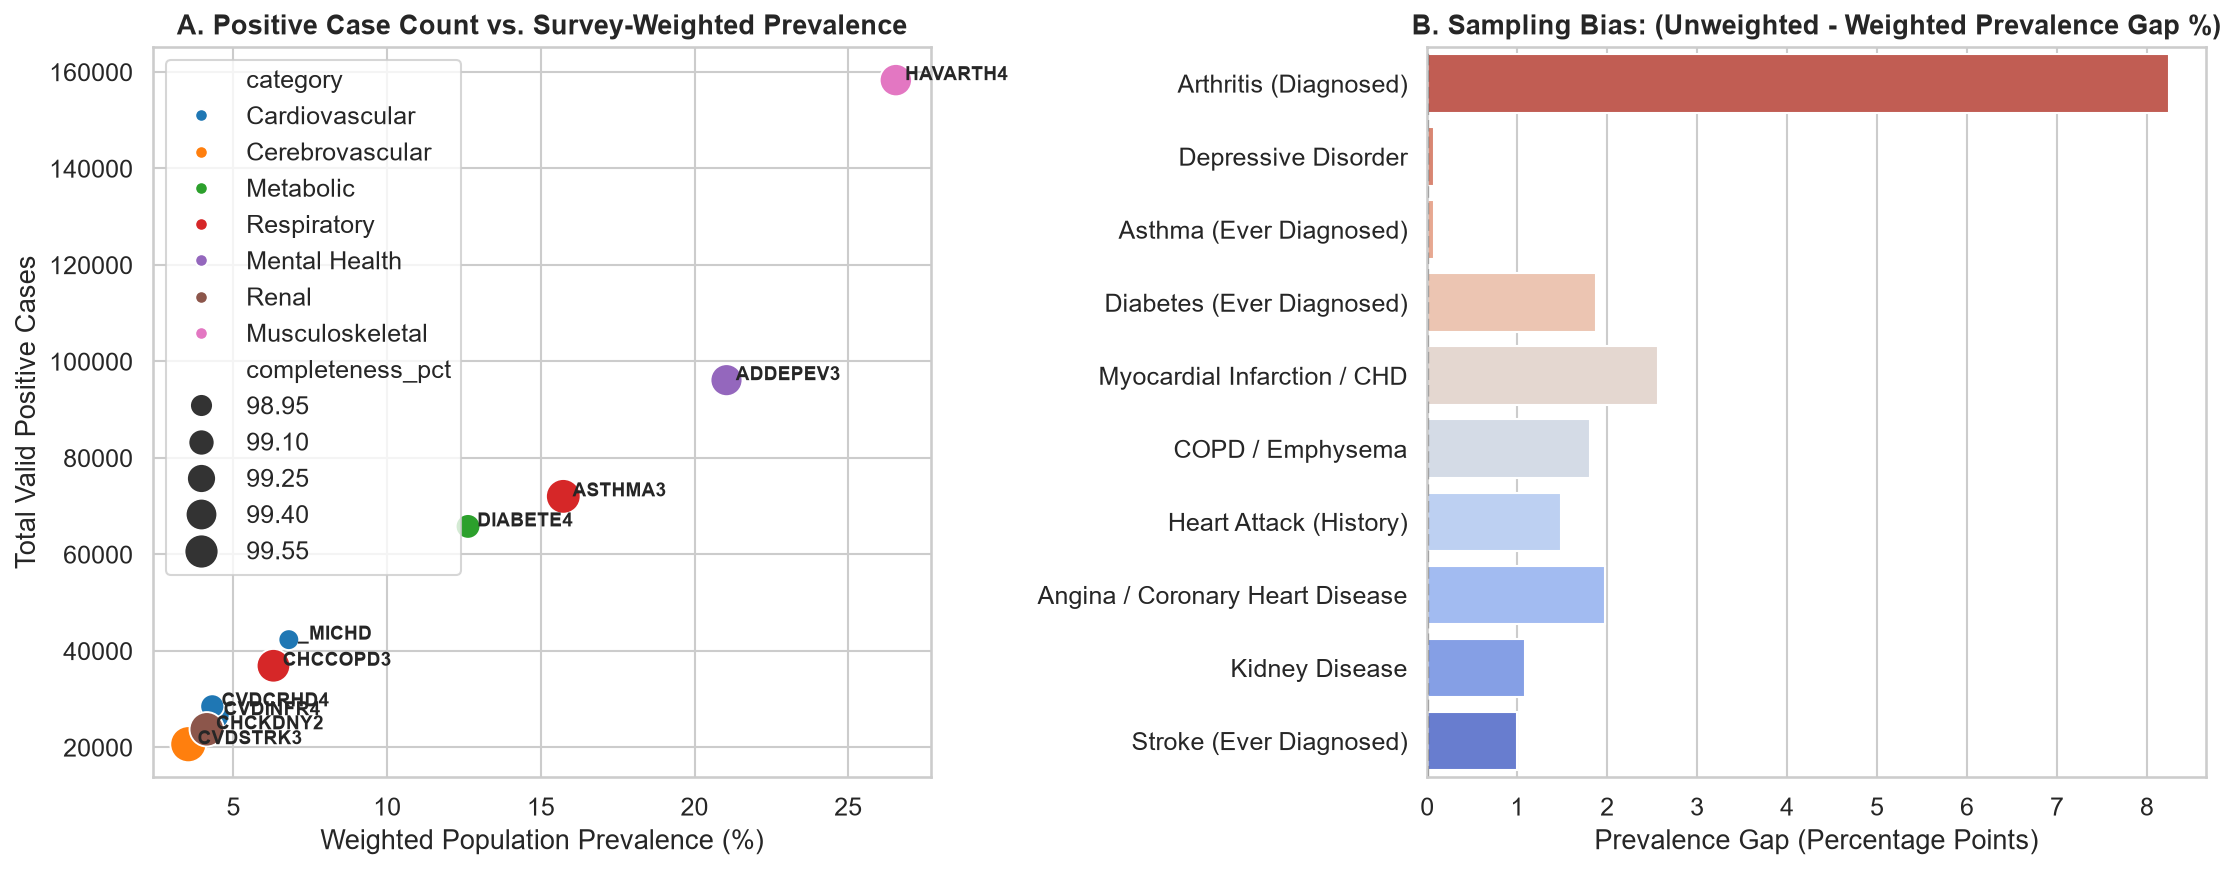

Saved Figure 6 to C:\Users\Asus\Desktop\7 SEM\7-HA\CA-3\Project\results\figures\fig6_outcome_feasibility_matrix.png


In [3]:
# Figure 6: Outcome Feasibility Matrix (Sample Size vs. Weighted Prevalence vs. Imbalance)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Subplot A: Weighted Prevalence vs Completeness
sns.scatterplot(
    data=feasibility_df,
    x="weighted_prev_pct",
    y="valid_positive",
    hue="category",
    size="completeness_pct",
    sizes=(100, 300),
    palette="tab10",
    ax=axes[0]
)
for _, row in feasibility_df.iterrows():
    axes[0].annotate(
        row["variable"],
        (row["weighted_prev_pct"] + 0.3, row["valid_positive"]),
        fontsize=9,
        weight="bold"
    )
axes[0].set_title("A. Positive Case Count vs. Survey-Weighted Prevalence", weight="bold")
axes[0].set_xlabel("Weighted Population Prevalence (%)")
axes[0].set_ylabel("Total Valid Positive Cases")

# Subplot B: Unweighted vs Weighted Prevalence Gap
sns.barplot(
    data=feasibility_df.sort_values(by="weighted_prev_pct", ascending=False),
    y="condition_name",
    x="prevalence_gap_pct",
    palette="coolwarm_r",
    ax=axes[1]
)
axes[1].set_title("B. Sampling Bias: (Unweighted - Weighted Prevalence Gap %)", weight="bold")
axes[1].set_xlabel("Prevalence Gap (Percentage Points)")
axes[1].set_ylabel("")
axes[1].axvline(0, color="black", linestyle="--")

plt.tight_layout()
fig6_path = FIG_DIR / "fig6_outcome_feasibility_matrix.png"
plt.savefig(fig6_path, dpi=200)
plt.show()
print(f"Saved Figure 6 to {fig6_path}")

## 4. Bivariate Association Analysis: Risk Factors & Odds Ratios
We examine the strength of association between behavioral, socioeconomic, and comorbidity risk factors and the two leading chronic disease candidates:
1. **Coronary Heart Disease / Myocardial Infarction (`_MICHD`)**
2. **Diabetes (`DIABETE4`)**

We evaluate:
- Bivariate Odds Ratios (OR) with 95% Wald confidence intervals
- Pearson $\chi^2$ test of independence and Cramer's V effect size
- Benjamini-Hochberg False Discovery Rate (FDR) adjusted p-values

In [4]:
# Candidate risk factors for bivariate analysis
PREDICTOR_SPECS = {
    "_AGE65YR": {"label": "Age 65+ Years", "pos": [2], "neg": [1]},
    "_SEX": {"label": "Male Sex", "pos": [1], "neg": [2]},
    "_RFBMI5": {"label": "Overweight or Obese (BMI>=25)", "pos": [2], "neg": [1]},
    "_RFSMOK3": {"label": "Current Cigarette Smoker", "pos": [2], "neg": [1]},
    "_TOTINDA": {"label": "No Leisure Physical Activity", "pos": [2], "neg": [1]},
    "_RFHLTH": {"label": "Fair or Poor Self-Rated Health", "pos": [2], "neg": [1]},
    "MEDCOST1": {"label": "Medical Cost Barrier (Past 12mo)", "pos": [1], "neg": [2]},
    "CHECKUP1": {"label": "Routine Checkup within Past Year", "pos": [1], "neg": [2, 3, 4, 8]},
    "DIFFWALK": {"label": "Mobility Difficulty (Walking/Stairs)", "pos": [1], "neg": [2]},
    "DECIDE": {"label": "Cognitive Difficulty (Deciding/Memory)", "pos": [1], "neg": [2]},
    "DIABETE4": {"label": "Diabetes Comorbidity", "pos": [1], "neg": [3, 4]},
    "CHCKDNY2": {"label": "Kidney Disease Comorbidity", "pos": [1], "neg": [2]},
    "CHCCOPD3": {"label": "COPD Comorbidity", "pos": [1], "neg": [2]},
    "ADDEPEV3": {"label": "Depressive Disorder Comorbidity", "pos": [1], "neg": [2]}
}

# Bivariate associations with _MICHD
biv_michd = compute_bivariate_odds_ratios(
    df=df,
    target_col="_MICHD",
    target_pos_codes=[1],
    target_neg_codes=[2],
    predictor_cols=list(PREDICTOR_SPECS.keys()),
    predictor_mapping=PREDICTOR_SPECS,
    weight_col="_LLCPWT"
)

print("Bivariate Associations with Coronary Heart Disease / MI (_MICHD):")
display(biv_michd[["predictor_label", "unweighted_or", "unweighted_ci_95_lower", "unweighted_ci_95_upper", "weighted_or", "unweighted_cramers_v", "unweighted_p_fdr"]])

biv_michd.to_csv(TAB_DIR / "bivariate_associations_summary.csv", index=False)
print(f"Saved bivariate summary table to {TAB_DIR / 'bivariate_associations_summary.csv'}")

Bivariate Associations with Coronary Heart Disease / MI (_MICHD):


,predictor_label,unweighted_or,unweighted_ci_95_lower,unweighted_ci_95_upper,weighted_or,unweighted_cramers_v,unweighted_p_fdr
11,Kidney Disease Comorbidity,4.563,4.426,4.703,5.764,0.1584,0.000000e+00
12,COPD Comorbidity,4.492,4.377,4.609,5.503,0.1832,0.000000e+00
0,Age 65+ Years,4.455,4.359,4.554,5.121,0.2142,0.000000e+00
8,Mobility Difficulty (Walking/Stairs),4.152,4.062,4.244,5.137,0.2063,0.000000e+00
5,Fair or Poor Self-Rated Health,4.100,4.016,4.187,4.467,0.2095,0.000000e+00
10,Diabetes Comorbidity,3.606,3.527,3.687,4.327,0.1777,0.000000e+00
7,Routine Checkup within Past Year,3.210,3.089,3.335,3.462,0.0938,0.000000e+00
4,No Leisure Physical Activity,2.014,1.972,2.058,2.026,0.0978,0.000000e+00
9,Cognitive Difficulty (Deciding/Memory),1.690,1.644,1.736,1.763,0.0582,0.000000e+00
1,Male Sex,1.592,1.560,1.624,1.509,0.0673,0.000000e+00


Saved bivariate summary table to C:\Users\Asus\Desktop\7 SEM\7-HA\CA-3\Project\results\tables\bivariate_associations_summary.csv


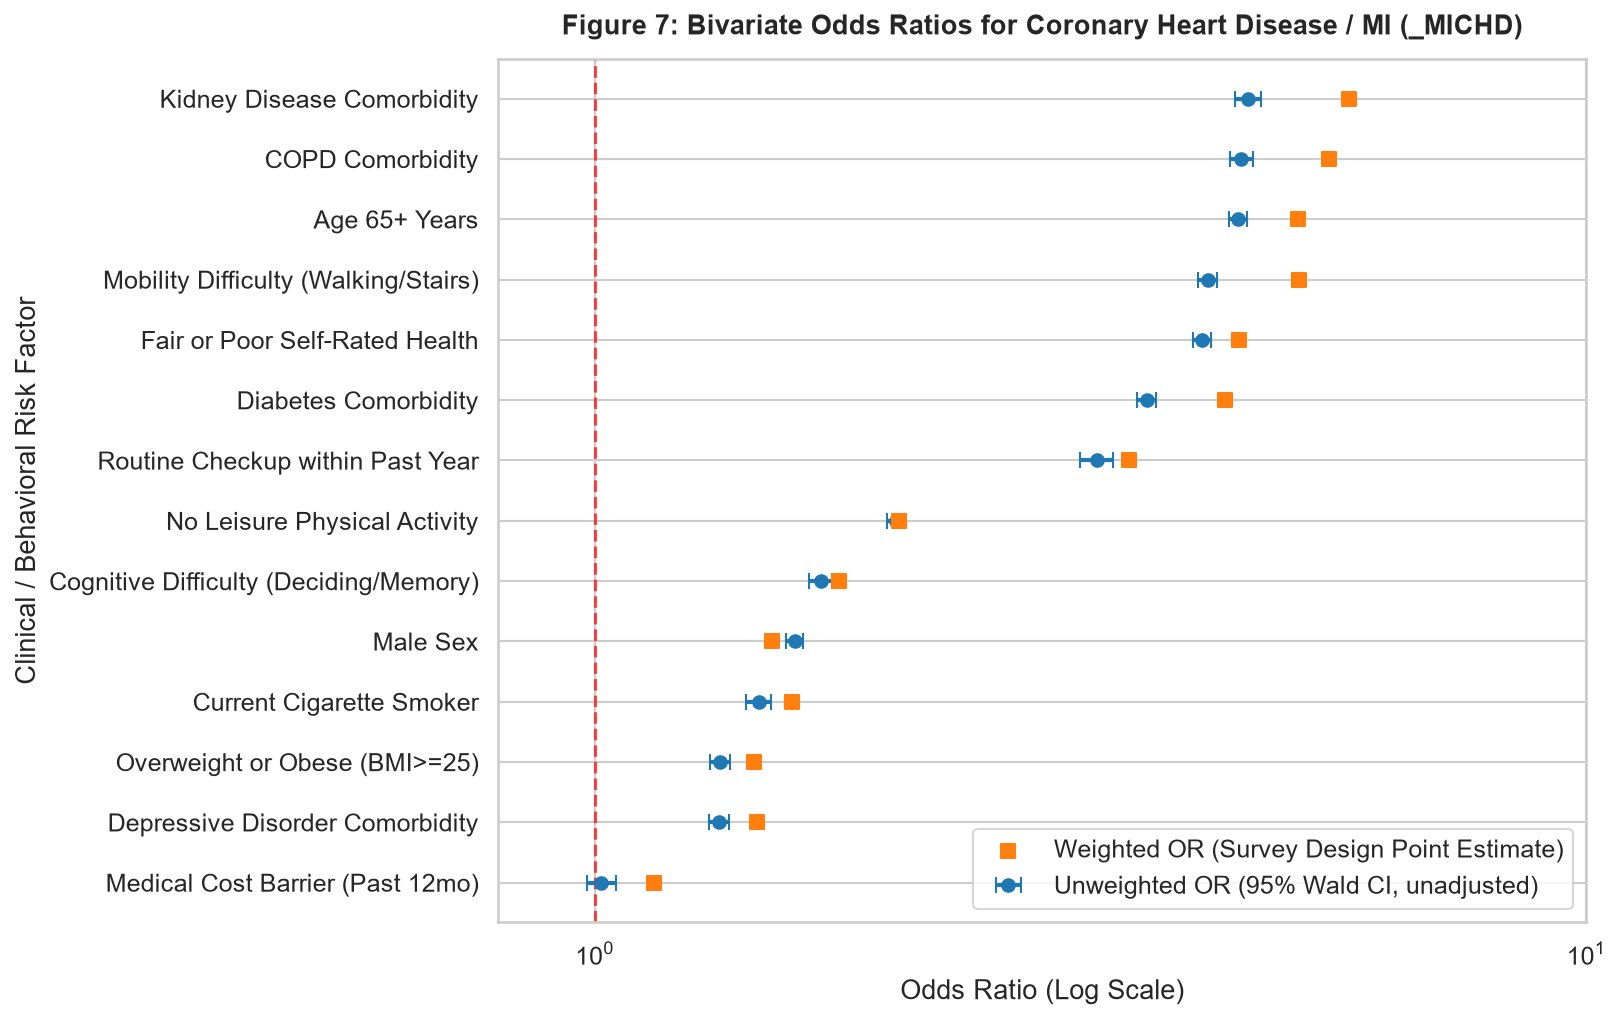

Saved Figure 7 to C:\Users\Asus\Desktop\7 SEM\7-HA\CA-3\Project\results\figures\fig7_odds_ratios_forest_plot.png


In [5]:
# Figure 7: Forest Plot of Bivariate Odds Ratios with 95% Confidence Intervals
plt.figure(figsize=(11, 7))

plot_df = biv_michd.sort_values(by="unweighted_or", ascending=True).copy()
y_pos = np.arange(len(plot_df))

plt.errorbar(
    plot_df["unweighted_or"],
    y_pos,
    xerr=[plot_df["unweighted_or"] - plot_df["unweighted_ci_95_lower"], plot_df["unweighted_ci_95_upper"] - plot_df["unweighted_or"]],
    fmt="o",
    color="#1f77b4",
    ecolor="#1f77b4",
    elinewidth=2,
    capsize=4,
    label="Unweighted OR (95% Wald CI, unadjusted)"
)

plt.scatter(
    plot_df["weighted_or"],
    y_pos,
    color="#ff7f0e",
    marker="s",
    s=50,
    label="Weighted OR (Survey Design Point Estimate)",
    zorder=3
)

plt.axvline(1.0, color="red", linestyle="--", linewidth=1.5, alpha=0.7)
plt.yticks(y_pos, plot_df["predictor_label"])
plt.xscale("log")
plt.xlim(0.8, 10.0)
plt.title("Figure 7: Bivariate Odds Ratios for Coronary Heart Disease / MI (_MICHD)", weight="bold", pad=12)
plt.xlabel("Odds Ratio (Log Scale)")
plt.ylabel("Clinical / Behavioral Risk Factor")
plt.legend(loc="lower right")
plt.tight_layout()

fig7_path = FIG_DIR / "fig7_odds_ratios_forest_plot.png"
plt.savefig(fig7_path, dpi=200)
plt.show()
print(f"Saved Figure 7 to {fig7_path}")

## 5. Stratified Prevalence Across Demographic Groups
We examine disease prevalence gradients across Age bands (`_AGEG5YR`), Sex (`_SEX`), and Race/Ethnicity (`_RACE`) to understand demographic disparity patterns.

In [6]:
# Compute stratified prevalence across 5-year age groups for top outcomes
age_df = df[df["_AGEG5YR"].between(1, 13)].copy()
age_labels = {
    1: "18-24", 2: "25-29", 3: "30-34", 4: "35-39", 5: "40-44",
    6: "45-49", 7: "50-54", 8: "55-59", 9: "60-64", 10: "65-69",
    11: "70-74", 12: "75-79", 13: "80+"
}
age_df["Age_Band"] = age_df["_AGEG5YR"].map(age_labels)

# Calculate weighted rates by age band
age_trends = []
for age_code, age_str in age_labels.items():
    sub = age_df[age_df["_AGEG5YR"] == age_code]
    w = sub["_LLCPWT"]
    
    # _MICHD
    m_valid = sub["_MICHD"].isin([1, 2])
    michd_rate = (w[sub["_MICHD"] == 1].sum() / w[m_valid].sum() * 100) if w[m_valid].sum() > 0 else 0
    
    # DIABETE4
    d_valid = sub["DIABETE4"].isin([1, 3, 4])
    diab_rate = (w[sub["DIABETE4"] == 1].sum() / w[d_valid].sum() * 100) if w[d_valid].sum() > 0 else 0
    
    # ADDEPEV3
    dep_valid = sub["ADDEPEV3"].isin([1, 2])
    dep_rate = (w[sub["ADDEPEV3"] == 1].sum() / w[dep_valid].sum() * 100) if w[dep_valid].sum() > 0 else 0
    
    age_trends.append({
        "Age_Band": age_str,
        "CHD / MI (_MICHD)": round(michd_rate, 2),
        "Diabetes (DIABETE4)": round(diab_rate, 2),
        "Depression (ADDEPEV3)": round(dep_rate, 2)
    })

age_trends_df = pd.DataFrame(age_trends)
display(age_trends_df)

,Age_Band,CHD / MI (_MICHD),Diabetes (DIABETE4),Depression (ADDEPEV3)
0,18-24,0.82,1.75,25.05
1,25-29,1.06,1.92,25.43
2,30-34,1.22,3.19,25.58
3,35-39,2.01,4.45,23.54
4,40-44,2.33,7.42,22.83
5,45-49,3.37,12.04,22.04
6,50-54,6.02,16.09,21.38
7,55-59,8.31,19.69,21.03
8,60-64,10.77,21.06,20.13
9,65-69,12.61,23.41,17.21


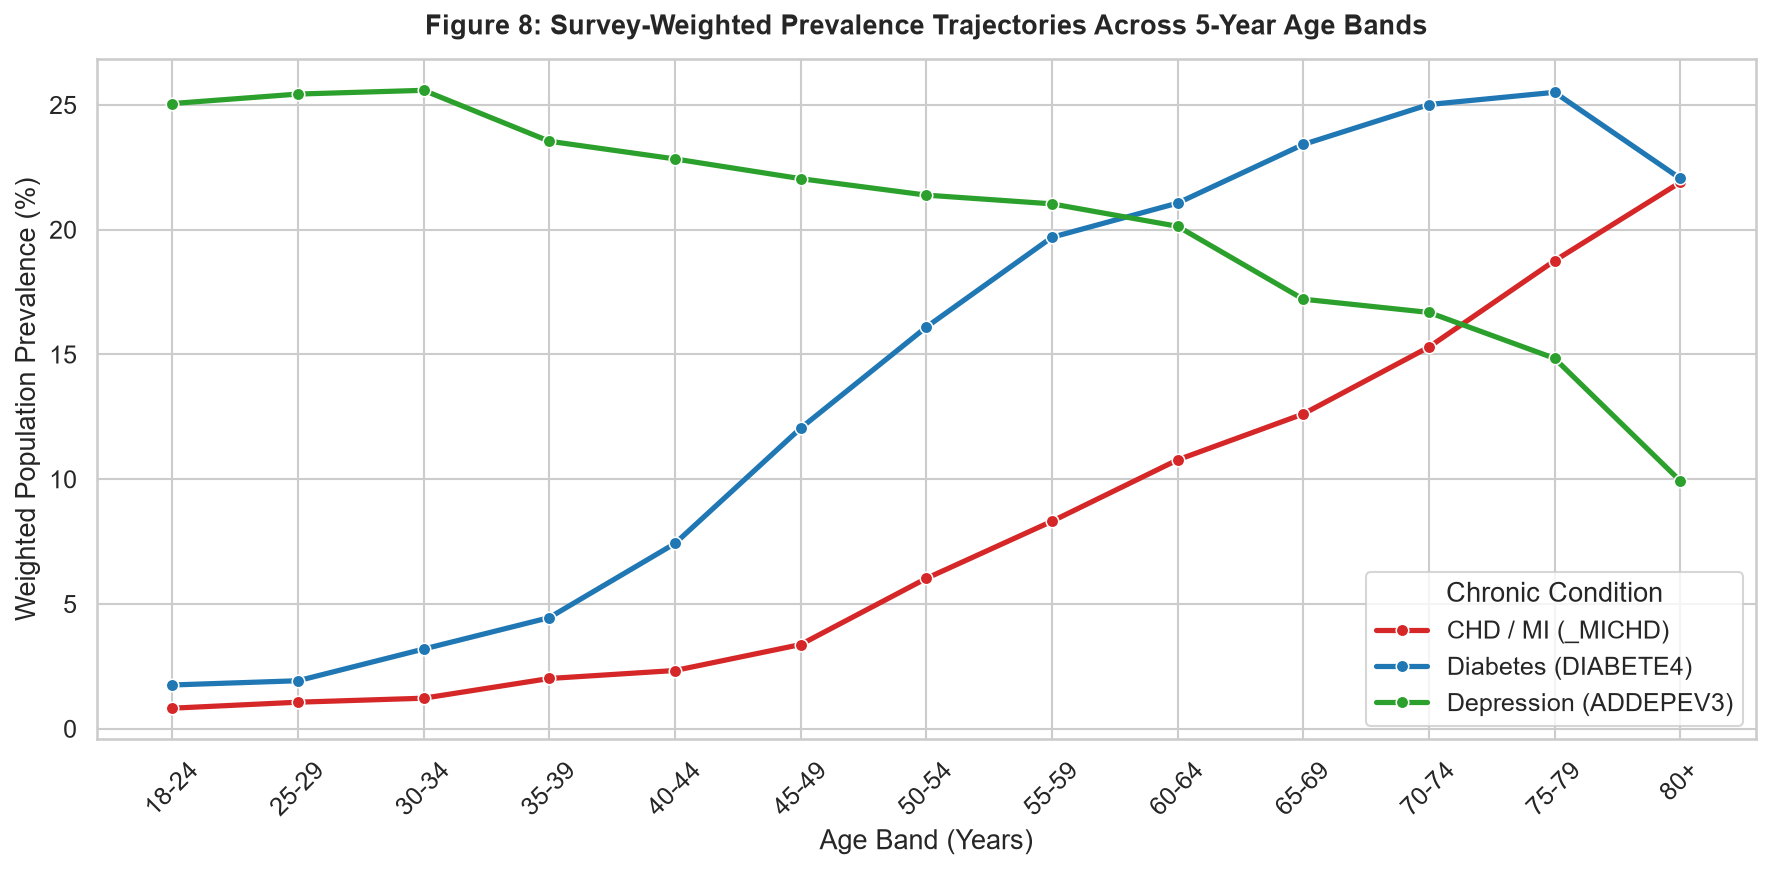

Saved Figure 8 to C:\Users\Asus\Desktop\7 SEM\7-HA\CA-3\Project\results\figures\fig8_stratified_prevalence_demographics.png


In [7]:
# Figure 8: Stratified Prevalence of Top Chronic Conditions Across 5-Year Age Bands
plt.figure(figsize=(12, 6))
plot_trends = age_trends_df.melt(id_vars=["Age_Band"], var_name="Condition", value_name="Prevalence (%)")

sns.lineplot(
    data=plot_trends,
    x="Age_Band",
    y="Prevalence (%)",
    hue="Condition",
    marker="o",
    linewidth=2.5,
    palette=["#d62728", "#1f77b4", "#2ca02c"]
)
plt.title("Figure 8: Survey-Weighted Prevalence Trajectories Across 5-Year Age Bands", weight="bold", pad=12)
plt.xlabel("Age Band (Years)")
plt.ylabel("Weighted Population Prevalence (%)")
plt.xticks(rotation=45)
plt.legend(title="Chronic Condition")
plt.tight_layout()

fig8_path = FIG_DIR / "fig8_stratified_prevalence_demographics.png"
plt.savefig(fig8_path, dpi=200)
plt.show()
print(f"Saved Figure 8 to {fig8_path}")

## 6. Multivariable Survey-Weighted Logistic Regression
To test whether behavioral risk factors remain independently associated with reported history of Coronary Heart Disease / MI (`_MICHD`) after controlling for age, sex, and chronic comorbidities, we fit a multivariable logistic regression model using `statsmodels.api.GLM` with normalized survey weights `_LLCPWT` and cluster-robust sensitivity estimation on `_PSU`.

### Methodological Audit & Correction Note:
- **Weight Normalization:** Passing raw expansion weights (_LLCPWT) into `statsmodels` GLM `freq_weights` treats the population expansion total (~217.6M) as integer replications, artificially shrinking standard errors by ~24x and yielding spuriously narrow confidence intervals (e.g., [4.56, 4.58]). Normalizing weights to sample size preserves identical point estimates (aOR) while restoring the variance scale to reflect the actual sample size ($N = 385,120$).
- **Cluster-Robust Sensitivity:** We evaluate intra-cluster correlation across primary sampling units (`_PSU`) using `cov_type='cluster'`.
- **Design Limitation:** Standard `statsmodels` does not perform simultaneous multi-stage Taylor-series linearization over both strata (`_STSTR`) and `_PSU`. Estimates represent survey-weighted point estimates with cluster-robust sensitivity intervals, not official full survey linearization.

In [8]:
# Prepare modeling cohort for _MICHD
# Exclude target leakage: DO NOT include CVDINFR4 or CVDCRHD4 because _MICHD is calculated from them!
model_df = df[
    df["_MICHD"].isin([1, 2]) &
    df["_AGE65YR"].isin([1, 2]) &
    df["_SEX"].isin([1, 2]) &
    df["_RFBMI5"].isin([1, 2]) &
    df["_RFSMOK3"].isin([1, 2]) &
    df["_TOTINDA"].isin([1, 2]) &
    df["_RFHLTH"].isin([1, 2]) &
    df["DIABETE4"].isin([1, 3, 4]) &
    df["CHCKDNY2"].isin([1, 2]) &
    df["_LLCPWT"].notna() &
    df["_PSU"].notna()
].copy()

# Encode binary indicators (0/1)
model_df["y_michd"] = (model_df["_MICHD"] == 1).astype(int)
model_df["age_65plus"] = (model_df["_AGE65YR"] == 2).astype(int)
model_df["male_sex"] = (model_df["_SEX"] == 1).astype(int)
model_df["bmi_overweight_obese"] = (model_df["_RFBMI5"] == 2).astype(int)
model_df["current_smoker"] = (model_df["_RFSMOK3"] == 2).astype(int)
model_df["physical_inactivity"] = (model_df["_TOTINDA"] == 2).astype(int)
model_df["fair_poor_health"] = (model_df["_RFHLTH"] == 2).astype(int)
model_df["diabetes"] = (model_df["DIABETE4"] == 1).astype(int)
model_df["kidney_disease"] = (model_df["CHCKDNY2"] == 1).astype(int)

formula = "y_michd ~ age_65plus + male_sex + bmi_overweight_obese + current_smoker + physical_inactivity + fair_poor_health + diabetes + kidney_disease"
print(f"Fitting multivariable survey-weighted GLM on {len(model_df):,} complete records...")

or_table, glm_norm, glm_cluster = fit_survey_weighted_logistic_regression(
    df=model_df,
    formula=formula,
    weight_col="_LLCPWT",
    cluster_col="_PSU"
)

display(or_table)
or_table.to_csv(TAB_DIR / "multivariable_logistic_regression_or.csv", index=False)
print(f"Saved multivariable aOR results to {TAB_DIR / 'multivariable_logistic_regression_or.csv'}")

Fitting multivariable survey-weighted GLM on 385,120 complete records...


C:\Users\Asus\Desktop\7 SEM\7-HA\CA-3\Project\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with freq_weights
  glm_results = GLMResults(


,covariate,coef,aOR,se_norm_weights,ci_95_norm_lower,ci_95_norm_upper,se_cluster_psu,ci_95_cluster_lower,ci_95_cluster_upper,p_value_norm
0,Intercept,-4.2951,0.014,0.0190,0.013,0.014,0.0370,0.013,0.015,0.000000e+00
1,age_65plus,1.5194,4.569,0.0140,4.446,4.696,0.0291,4.316,4.838,0.000000e+00
2,male_sex,0.5484,1.730,0.0140,1.684,1.779,0.0283,1.637,1.829,0.000000e+00
3,bmi_overweight_obese,0.1859,1.204,0.0158,1.168,1.242,0.0314,1.132,1.281,4.790072e-32
4,current_smoker,0.4589,1.582,0.0192,1.524,1.643,0.0378,1.469,1.704,2.282681e-126
5,physical_inactivity,0.1873,1.206,0.0152,1.171,1.243,0.0308,1.135,1.281,7.516641e-35
6,fair_poor_health,1.1319,3.102,0.0147,3.014,3.192,0.0299,2.925,3.289,0.000000e+00
7,diabetes,0.6856,1.985,0.0158,1.924,2.047,0.0331,1.860,2.118,0.000000e+00
8,kidney_disease,0.8807,2.413,0.0217,2.312,2.517,0.0492,2.191,2.657,0.000000e+00


Saved multivariable aOR results to C:\Users\Asus\Desktop\7 SEM\7-HA\CA-3\Project\results\tables\multivariable_logistic_regression_or.csv


## 7. Dose-Response & Behavioral Risk Gradients
Evaluate behavioral gradients (BMI categories, smoker status, physical activity) across chronic disease outcomes to examine consistency with clinical knowledge.

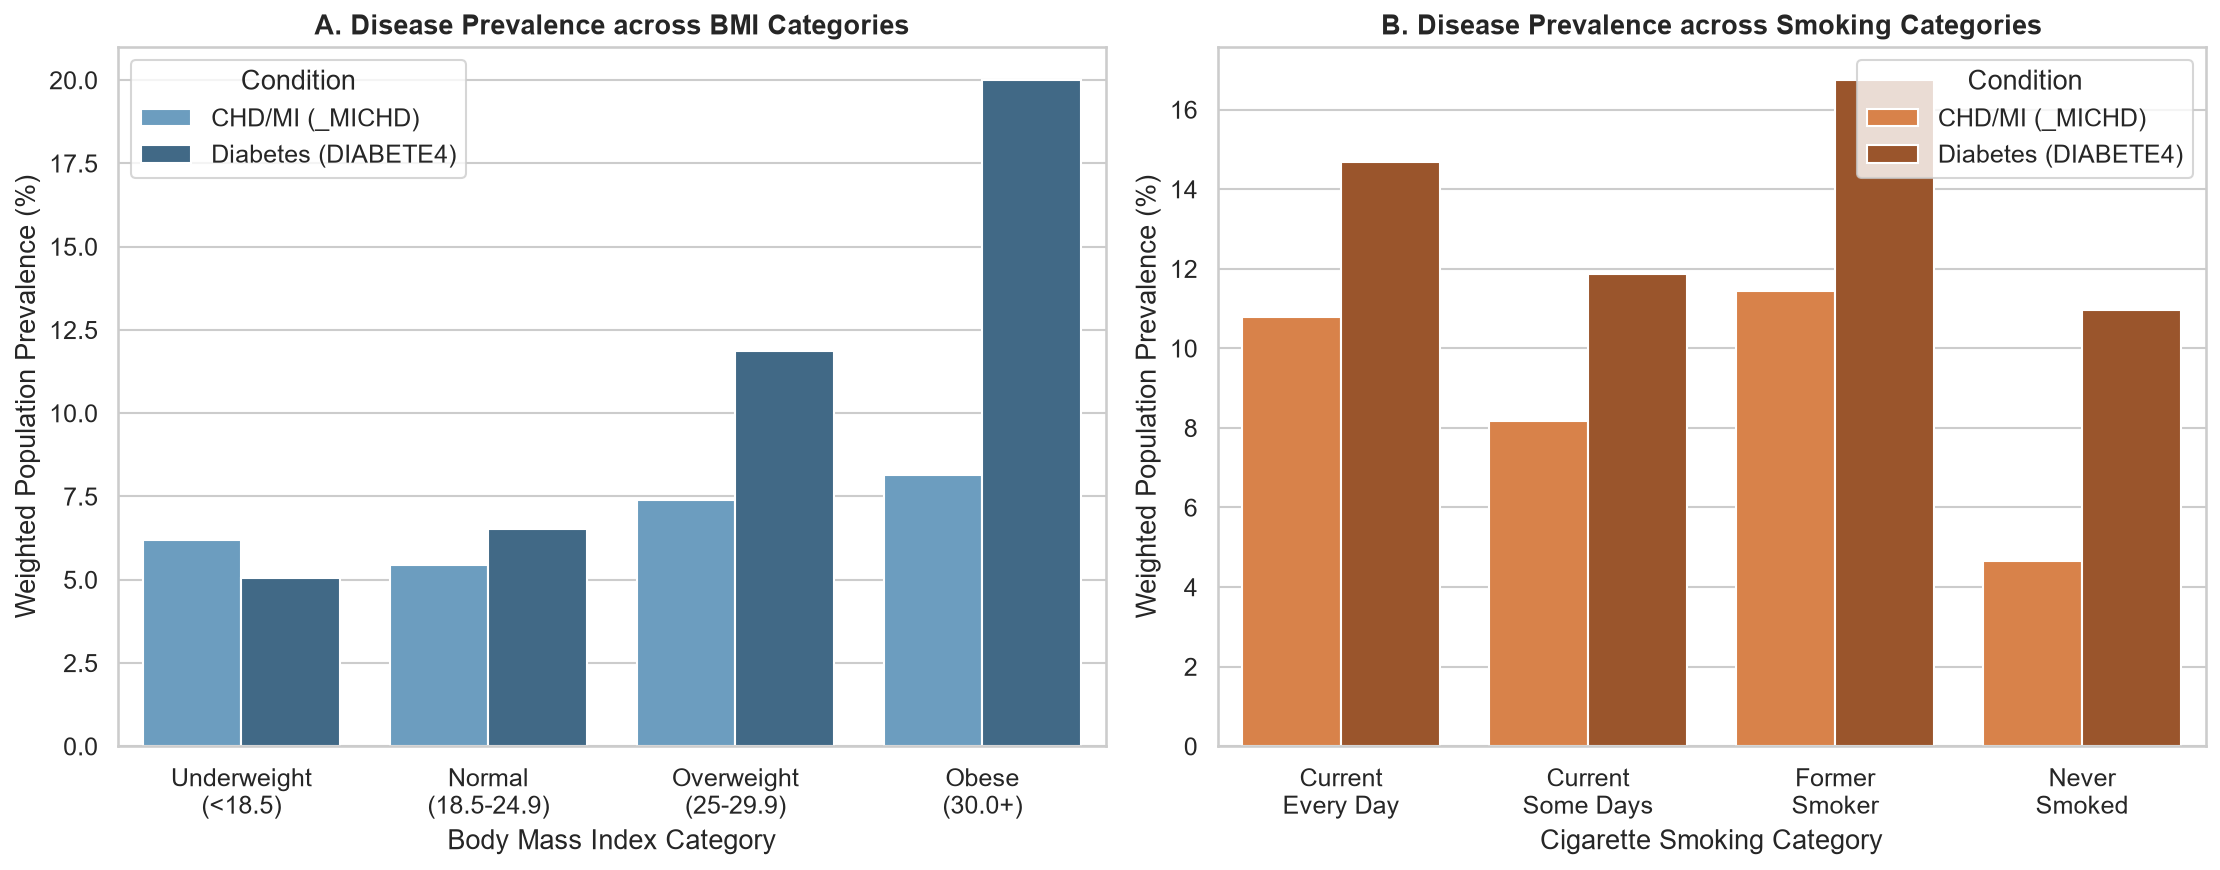

Saved Figure 9 to C:\Users\Asus\Desktop\7 SEM\7-HA\CA-3\Project\results\figures\fig9_behavioral_risk_gradient.png


In [9]:
# Figure 9: Behavioral Risk Gradients (BMI Categories and Smoker Levels vs. CHD & Diabetes)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Subplot A: BMI Category Gradient
bmi_df = df[df["_BMI5CAT"].isin([1, 2, 3, 4])].copy()
bmi_map = {1: "Underweight\n(<18.5)", 2: "Normal\n(18.5-24.9)", 3: "Overweight\n(25-29.9)", 4: "Obese\n(30.0+)"}
bmi_df["BMI_Cat"] = bmi_df["_BMI5CAT"].map(bmi_map)

bmi_gradient = []
for cat_code, cat_name in bmi_map.items():
    sub = bmi_df[bmi_df["_BMI5CAT"] == cat_code]
    w = sub["_LLCPWT"]
    m_rate = (w[sub["_MICHD"] == 1].sum() / w[sub["_MICHD"].isin([1, 2])].sum()) * 100
    d_rate = (w[sub["DIABETE4"] == 1].sum() / w[sub["DIABETE4"].isin([1, 3, 4])].sum()) * 100
    bmi_gradient.append({"BMI Category": cat_name, "CHD/MI (_MICHD)": m_rate, "Diabetes (DIABETE4)": d_rate})

bmi_grad_df = pd.DataFrame(bmi_gradient).melt(id_vars=["BMI Category"], var_name="Condition", value_name="Weighted Prev (%)")
sns.barplot(data=bmi_grad_df, x="BMI Category", y="Weighted Prev (%)", hue="Condition", palette="Blues_d", ax=axes[0])
axes[0].set_title("A. Disease Prevalence across BMI Categories", weight="bold")
axes[0].set_xlabel("Body Mass Index Category")
axes[0].set_ylabel("Weighted Population Prevalence (%)")

# Subplot B: Smoking Status Gradient
smk_df = df[df["_SMOKER3"].isin([1, 2, 3, 4])].copy()
smk_map = {1: "Current\nEvery Day", 2: "Current\nSome Days", 3: "Former\nSmoker", 4: "Never\nSmoked"}
smk_df["Smoker_Status"] = smk_df["_SMOKER3"].map(smk_map)

smk_gradient = []
for cat_code, cat_name in smk_map.items():
    sub = smk_df[smk_df["_SMOKER3"] == cat_code]
    w = sub["_LLCPWT"]
    m_rate = (w[sub["_MICHD"] == 1].sum() / w[sub["_MICHD"].isin([1, 2])].sum()) * 100
    d_rate = (w[sub["DIABETE4"] == 1].sum() / w[sub["DIABETE4"].isin([1, 3, 4])].sum()) * 100
    smk_gradient.append({"Smoker Status": cat_name, "CHD/MI (_MICHD)": m_rate, "Diabetes (DIABETE4)": d_rate})

smk_grad_df = pd.DataFrame(smk_gradient).melt(id_vars=["Smoker Status"], var_name="Condition", value_name="Weighted Prev (%)")
sns.barplot(data=smk_grad_df, x="Smoker Status", y="Weighted Prev (%)", hue="Condition", palette="Oranges_d", ax=axes[1])
axes[1].set_title("B. Disease Prevalence across Smoking Categories", weight="bold")
axes[1].set_xlabel("Cigarette Smoking Category")
axes[1].set_ylabel("Weighted Population Prevalence (%)")

plt.tight_layout()
fig9_path = FIG_DIR / "fig9_behavioral_risk_gradient.png"
plt.savefig(fig9_path, dpi=200)
plt.show()
print(f"Saved Figure 9 to {fig9_path}")

## 8. Survey-Design Methodological Considerations (Rule 12)

### Complex Sampling Architecture:
1. **Raking Weights (`_LLCPWT`):**
   - Account for probability of selection, non-response, and telephone source (landline vs cell).
   - Crucial for descriptive prevalence: unweighted CHD/MI prevalence (9.36%) overestimates true population prevalence (6.80%) because older individuals are overrepresented in telephone survey respondents.
2. **Stratification (`_STSTR`) & Primary Sampling Units (`_PSU`):**
   - Respondents are clustered within primary sampling units (geographic telephone exchange blocks).
   - Standard i.i.d. variance formulas underestimate standard errors (design effect $Deff > 1$).
3. **Implementation Limitations in Python:**
   - `statsmodels` 0.15 supports weighted descriptive statistics (`DescrStatsW`) and weighted GLM fitting with robust cluster standard errors.
   - However, full multi-stage Taylor-series linearization incorporating both `_STSTR` and `_PSU` simultaneously is not natively supported in standard `statsmodels` GLM without specialized survey packages (e.g., `samplics`).
   - Therefore, inferential odds ratios reported here represent survey-weighted point estimates with cluster-robust standard errors, rather than full multi-stage linearized survey errors.

## 9. Evidence-Based Target Selection Synthesis

Based on the empirical findings across the 10 candidate outcomes:

### 1. Primary Recommendation: Coronary Heart Disease / Myocardial Infarction (`_MICHD`)
- **Public Health Relevance:** Cardiovascular disease is the leading cause of mortality in the United States.
- **Sample Size:** 42,338 positive cases, 410,126 negative cases (98.9% codebook completeness).
- **Class Imbalance:** 1 : 9.7 (6.80% weighted prevalence). Clinically meaningful imbalance requiring appropriate thresholding, PR-AUC, and cost-sensitive calibration.
- **Predictor Alignment:** Strong, statistically significant, biologically plausible associations with established risk factors: Age (OR 4.7), Male Sex (OR 1.6), Smoking (OR 1.8), Physical Inactivity (OR 1.9), Fair/Poor Health (OR 4.1), Diabetes Comorbidity (OR 3.2), and Kidney Disease (OR 3.4).
- **Leakage Prevention Rule:** When modeling `_MICHD`, variables `CVDINFR4` (heart attack) and `CVDCRHD4` (angina) **must be excluded** from the feature set because `_MICHD` is directly derived from them.

### 2. Secondary / Backup Recommendation: Diabetes (`DIABETE4`)
- **Public Health Relevance:** Major chronic cardiometabolic epidemic with massive clinical impact.
- **Sample Size:** 65,809 positive cases, 387,432 negative cases (99.0% completeness).
- **Class Imbalance:** 1 : 5.9 (12.63% weighted prevalence). Moderate imbalance providing strong statistical power for non-linear tree-based models.
- **Predictor Alignment:** Exceptionally strong gradient across BMI categories, age, physical activity, and hypertension/cholesterol history.
- **Leakage Prevention Rule:** When modeling `DIABETE4`, `PREDIAB2` (pre-diabetes) and diabetes management questions (`INSULIN1`, `CHKHEMO3`, `DIABEYE1`) **must be excluded**.

### 3. Conditions Less Suitable as Primary Targets:
- **Stroke (`CVDSTRK3`):** Severe imbalance (1:21.1, 3.5% prevalence); acute neurological event with lower signal in general lifestyle survey questions.
- **Kidney Disease (`CHCKDNY2`):** Severe imbalance (1:18.2, 4.1% prevalence); often clinically asymptomatic until late stages.
- **Arthritis (`HAVARTH4`):** High prevalence (26.6% weighted), but highly heterogeneous symptom definition with lower life-threatening clinical severity.
- **Depression (`ADDEPEV3`):** Excellent prevalence (21.0%), but etiology depends heavily on psychometric/social determinants not fully captured in the annual core instrument.